1. Load Data Set

In [64]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')
friends= pd.read_csv("/content/drive/MyDrive/Friends.csv")
friends.head()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Text,Speaker,Episode,Season,Show
0,Originally written by Marta Kauffman and David...,NaN,Episode-01-The One Where Monica Gets a New Roo...,Season-01,Friends
1,Transcribed by guineapig.,NaN,Episode-01-The One Where Monica Gets a New Roo...,Season-01,Friends
2,CENTRAL PERK. (ALL PRESENT EXCEPT RACHEL AND ...,SCENE 1,Episode-01-The One Where Monica Gets a New Roo...,Season-01,Friends
3,There's nothing to tell! He's just some guy I...,MONICA,Episode-01-The One Where Monica Gets a New Roo...,Season-01,Friends
4,"C'mon, you're going out with the guy! There's...",JOEY,Episode-01-The One Where Monica Gets a New Roo...,Season-01,Friends


2. Start pre-processing

In [65]:
## Filter Joey
friends_Joey = friends[friends["Speaker"].str.upper() == "JOEY"].copy()
friends_Joey.head()

,Text,Speaker,Episode,Season,Show
4,"C'mon, you're going out with the guy! There's...",JOEY,Episode-01-The One Where Monica Gets a New Roo...,Season-01,Friends
15,Instead of...?,JOEY,Episode-01-The One Where Monica Gets a New Roo...,Season-01,Friends
17,Never had that dream.,JOEY,Episode-01-The One Where Monica Gets a New Roo...,Season-01,Friends
22,"This guy says hello, I wanna kill myself.",JOEY,Episode-01-The One Where Monica Gets a New Roo...,Season-01,Friends
31,And you never knew she was a lesbian...,JOEY,Episode-01-The One Where Monica Gets a New Roo...,Season-01,Friends


In [66]:
print(friends_Joey.loc[53980, "Text"])

 Oh okay, okay! One more push! One more push! Come on honey, weâ€™re almost there! Weâ€™re almost there!


Fix encoding problem

In [67]:
friends_Joey["Text"] = (
    friends_Joey["Text"]
    .str.replace("â€™", "'", regex=False)
    .str.replace("â€˜", "'", regex=False)
    .str.replace("â€¦", "...", regex=False)
    .str.replace("â€œ", '"', regex=False)
    .str.replace("â€\x9d", '"', regex=False)
    .str.replace("â€”", "-", regex=False)
)

In [68]:
print(friends_Joey.loc[53980, "Text"])

 Oh okay, okay! One more push! One more push! Come on honey, we're almost there! We're almost there!


More cleaning

In [99]:
friends_Joey["Text"] = (
    friends_Joey["Text"]
    .str.lower() #lower case
    .str.replace(r"\[[^\]]*\]", "", regex=True) #deletes statge directions
    .str.replace(r"\([^)]*\)", "", regex=True) #deletes statge directions
    .str.replace(r"\b(\w+)'re\b", r"\1 are", regex=True) # contractions: what're -> what are, how're -> how are, you're -> you are
    .str.replace(r"\b(\w+)'ve\b", r"\1 have", regex=True)# contractions: should've -> should have, i've -> i have
    .str.replace(r"\b(\w+)'ll\b", r"\1 will", regex=True)# contractions: that'll -> that will, we'll -> we will
    .str.replace(r"\b(\w+)'m\b", r"\1 am", regex=True)   # contractions: i'm -> i am
    .str.replace(r"\b(\w+)'d\b", r"\1 would", regex=True)# i'd -> i would, you'd -> you would
)

In [100]:
print(friends_Joey.loc[53980, "Text"])

 oh okay, okay! one more push! one more push! come on honey, we are almost there! we are almost there!


In [101]:
## Sentence and word tokenization
import re

sentence_spliter = re.compile(r'[.!?] ')
word_spliter = re.compile(r"[\w']+")

sentences = []
words = []

for text in friends_Joey["Text"]:
  sentences.append(sentence_spliter.split(text))
  words.append(word_spliter.findall(text))

friends_Joey["Sentences"] = sentences
friends_Joey["Words"] = words

print("TEXT:", friends_Joey.loc[2084, "Text"])
print("SENTENCES:", friends_Joey.loc[2084, "Sentences"])
print("WORDS:", friends_Joey.loc[2084, "Words"])

TEXT:  now, see, i do not believe any of that. i think once you are dead, you are dead! you are gone! you are worm food!  ...so chandler looks gay, huh?
SENTENCES: [' now, see, i do not believe any of that', 'i think once you are dead, you are dead', 'you are gone', 'you are worm food', ' ...so chandler looks gay, huh?']
WORDS: ['now', 'see', 'i', 'do', 'not', 'believe', 'any', 'of', 'that', 'i', 'think', 'once', 'you', 'are', 'dead', 'you', 'are', 'dead', 'you', 'are', 'gone', 'you', 'are', 'worm', 'food', 'so', 'chandler', 'looks', 'gay', 'huh']


In [102]:

## Remove punctuations using a regular expression + lower case
punctuation_pattern = re.compile(r"[!”#$%&()*+,\-.:;?@\[\]\\^_‘{|}~’]")
friends_Joey["Sentences"] = friends_Joey["Sentences"].apply(
    lambda sentence_list: [punctuation_pattern.sub("",sentence) for sentence in sentence_list]
)
friends_Joey["Words"] = friends_Joey["Words"].apply(
    lambda word_list: [punctuation_pattern.sub("",word) for word in word_list])

print("TEXT:", friends_Joey.loc[2084, "Text"])
print("SENTENCES:", friends_Joey.loc[2084, "Sentences"])
print("WORDS:", friends_Joey.loc[2084, "Words"])

TEXT:  now, see, i do not believe any of that. i think once you are dead, you are dead! you are gone! you are worm food!  ...so chandler looks gay, huh?
SENTENCES: [' now see i do not believe any of that', 'i think once you are dead you are dead', 'you are gone', 'you are worm food', ' so chandler looks gay huh']
WORDS: ['now', 'see', 'i', 'do', 'not', 'believe', 'any', 'of', 'that', 'i', 'think', 'once', 'you', 'are', 'dead', 'you', 'are', 'dead', 'you', 'are', 'gone', 'you', 'are', 'worm', 'food', 'so', 'chandler', 'looks', 'gay', 'huh']


In [103]:
## Import stop words
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')
print(stopwords.words('english'))

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", 'her', 'here', 'hers', 'herself', "he's", 'him', 'himself', 'his', 'how', 'i', "i'd", 'if', "i'll", "i'm", 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', "i've", 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's', 'same', 'shan', "shan't", 'she

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [104]:
## Remove stop words
stop_words = set(stopwords.words('english'))
friends_Joey["Words"] = friends_Joey["Words"].apply(
    lambda word_list: [word for word in word_list if word not in stop_words]
)
friends_Joey["Sentences"] = friends_Joey["Sentences"].apply(
    lambda sentence_list: [
        " ".join([w for w in sentence.split() if not w in stop_words])
        for sentence in sentence_list
    ]
)

print("TEXT:", friends_Joey.loc[2084, "Text"])
print("SENTENCES:", friends_Joey.loc[2084, "Sentences"])
print("WORDS:", friends_Joey.loc[2084, "Words"])

TEXT:  now, see, i do not believe any of that. i think once you are dead, you are dead! you are gone! you are worm food!  ...so chandler looks gay, huh?
SENTENCES: ['see believe', 'think dead dead', 'gone', 'worm food', 'chandler looks gay huh']
WORDS: ['see', 'believe', 'think', 'dead', 'dead', 'gone', 'worm', 'food', 'chandler', 'looks', 'gay', 'huh']


In [105]:
## Appply Porter Stemmer
# import stemming modules
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

# create a new list with words stemmed
ps = PorterStemmer()

friends_Joey["Words_stemmed"] = friends_Joey["Words"].apply(
    lambda word_list: [ps.stem(word) for word in word_list]
)

print("TEXT:", friends_Joey.loc[2084, "Text"])
print("SENTENCES:", friends_Joey.loc[2084, "Sentences"])
print("WORDS:", friends_Joey.loc[2084, "Words"])
print("WORDS_stemmed:", friends_Joey.loc[2084, "Words_stemmed"])


TEXT:  now, see, i do not believe any of that. i think once you are dead, you are dead! you are gone! you are worm food!  ...so chandler looks gay, huh?
SENTENCES: ['see believe', 'think dead dead', 'gone', 'worm food', 'chandler looks gay huh']
WORDS: ['see', 'believe', 'think', 'dead', 'dead', 'gone', 'worm', 'food', 'chandler', 'looks', 'gay', 'huh']
WORDS_stemmed: ['see', 'believ', 'think', 'dead', 'dead', 'gone', 'worm', 'food', 'chandler', 'look', 'gay', 'huh']


In [106]:
## POS Tagging & NER
#!python -m spacy download en_core_web_lg
import spacy

#POS
nlp = spacy.load("en_core_web_lg")
friends_Joey["POS"] = friends_Joey["Text"].apply(
    lambda text: [[token.text, token.pos_] for token in nlp(text)]
)
friends_Joey["NER"] = friends_Joey["Text"].apply(
    lambda text: [[token.text, token.label_] for token in nlp(text).ents]
)

#NER
#for ent in doc.ents:
#    print(ent.text, ent.start_char, ent.end_char, ent.label_)

print("TEXT:", friends_Joey.loc[2084, "Text"])
print("POS:", friends_Joey.loc[2084, "POS"])
print("NER:", friends_Joey.loc[2084,"NER"])

TEXT:  now, see, i do not believe any of that. i think once you are dead, you are dead! you are gone! you are worm food!  ...so chandler looks gay, huh?
POS: [[' ', 'SPACE'], ['now', 'ADV'], [',', 'PUNCT'], ['see', 'VERB'], [',', 'PUNCT'], ['i', 'PRON'], ['do', 'AUX'], ['not', 'PART'], ['believe', 'VERB'], ['any', 'PRON'], ['of', 'ADP'], ['that', 'PRON'], ['.', 'PUNCT'], ['i', 'PRON'], ['think', 'VERB'], ['once', 'SCONJ'], ['you', 'PRON'], ['are', 'AUX'], ['dead', 'ADJ'], [',', 'PUNCT'], ['you', 'PRON'], ['are', 'AUX'], ['dead', 'ADJ'], ['!', 'PUNCT'], ['you', 'PRON'], ['are', 'AUX'], ['gone', 'VERB'], ['!', 'PUNCT'], ['you', 'PRON'], ['are', 'AUX'], ['worm', 'NOUN'], ['food', 'NOUN'], ['!', 'PUNCT'], [' ', 'SPACE'], ['...', 'PUNCT'], ['so', 'ADV'], ['chandler', 'PROPN'], ['looks', 'VERB'], ['gay', 'ADJ'], [',', 'PUNCT'], ['huh', 'INTJ'], ['?', 'PUNCT']]
NER: [['chandler', 'PERSON']]


1. On average, how many sentences and words does your character have to speak per
episode? Does this deviate across seasons?

In [107]:
##Num words & Sentences per row
friends_Joey['Num_Words'] = friends_Joey['Words'].apply(len)
friends_Joey['Num_Sentences'] = friends_Joey['Sentences'].apply(len)

#Group by Episode/Season
episodes_stats = friends_Joey.groupby(['Season', 'Episode'])[['Num_Words', 'Num_Sentences']].sum().reset_index()

## average word/sentence per episode
average_words = episodes_stats['Num_Words'].mean()
average_sentences = episodes_stats['Num_Sentences'].mean()

print(average_words)
print(average_sentences)

#average per season
average_per_season = episodes_stats.groupby('Season')[['Num_Words', 'Num_Sentences']].mean()
print(average_per_season)

184.85777777777778
69.09333333333333
            Num_Words  Num_Sentences
Season                              
Season-01  125.041667      47.375000
Season-02  157.608696      49.130435
Season-03  157.160000      52.160000
Season-04  173.782609      65.565217
Season-05  210.869565      80.260870
Season-06  231.217391      83.608696
Season-07  203.260870      81.782609
Season-08  216.782609      84.782609
Season-09  187.304348      71.434783
Season-10  193.600000      81.600000


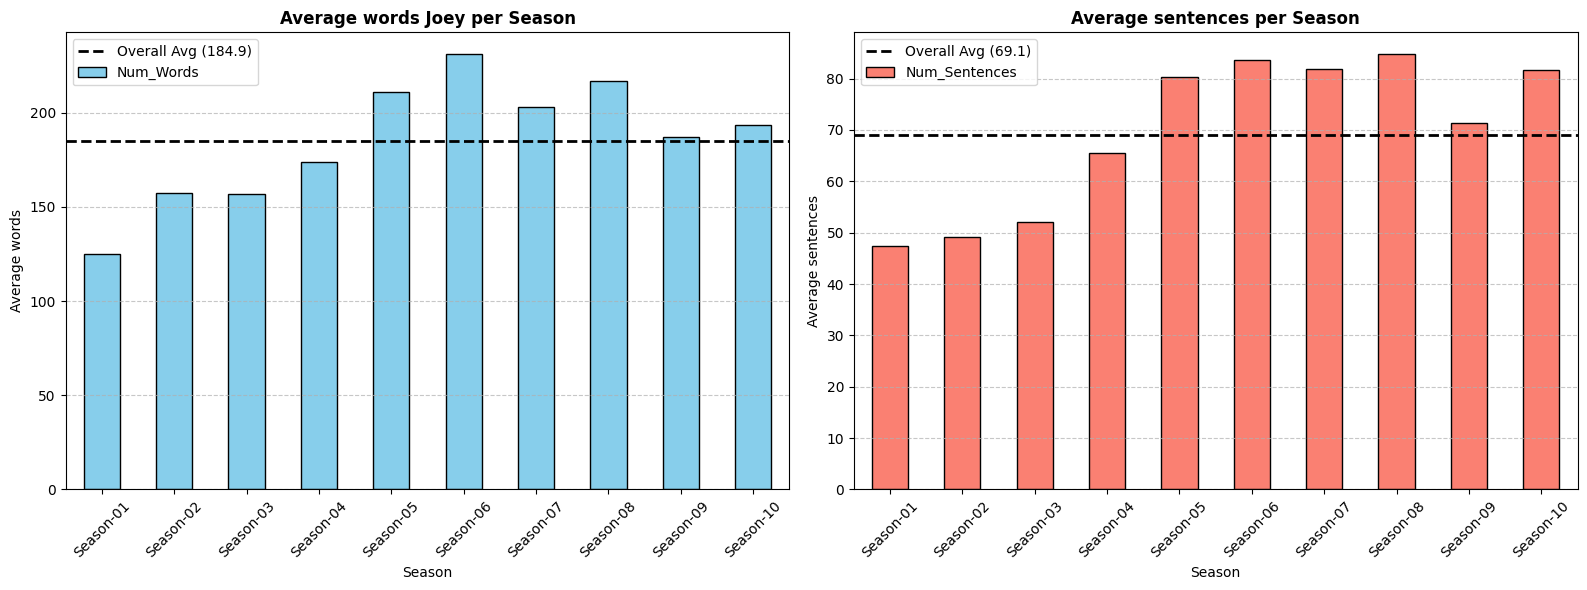

In [108]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Graph avg words
average_per_season['Num_Words'].plot(kind='bar', ax=axes[0], color='skyblue', edgecolor='black')
axes[0].set_title('Average words Joey per Season', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Season')
axes[0].set_ylabel('Average words')
axes[0].set_xticklabels(average_per_season.index, rotation=45)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)
axes[0].axhline(y=average_words, color='black', linestyle='--', linewidth=2, label=f'Overall Avg ({average_words:.1f})')
axes[0].legend()

# Graph avg sentences
average_per_season['Num_Sentences'].plot(kind='bar', ax=axes[1], color='salmon', edgecolor='black')
axes[1].set_title('Average sentences per Season', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Season')
axes[1].set_ylabel('Average sentences')
axes[1].set_xticklabels(average_per_season.index, rotation=45)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)
axes[1].axhline(y=average_sentences, color='black', linestyle='--', linewidth=2, label=f'Overall Avg ({average_sentences:.1f})')
axes[1].legend()

plt.tight_layout()
plt.show()

**Answer:** On average Joey speaks 185 words (without coutning stop-words) and 69 sentences per chapter. This variates throughout the different seasons. As shown in the graphs, the first seasons he speaks less, the peak of words is in season 6, and the peak of sentences in season 8.

2. Globally, over all episodes within all 10 seasons, how many times does your character
mention nouns, and person names? Make a Wordcloud of this tag/entity to have a
clear visualization which nouns/person names are mostly used by your character.

In [111]:
#Count Nouns
total_nouns = sum(
    1 for pos_list in friends_Joey["POS"]
    for token, pos in pos_list if pos in ["NOUN"]
)

# Count Persons in NER
total_persons = sum(
    1 for ner_list in friends_Joey["NER"]
    for entity, label in ner_list if label == "PERSON"
)

print(total_nouns)
print(total_persons)

10766
1562


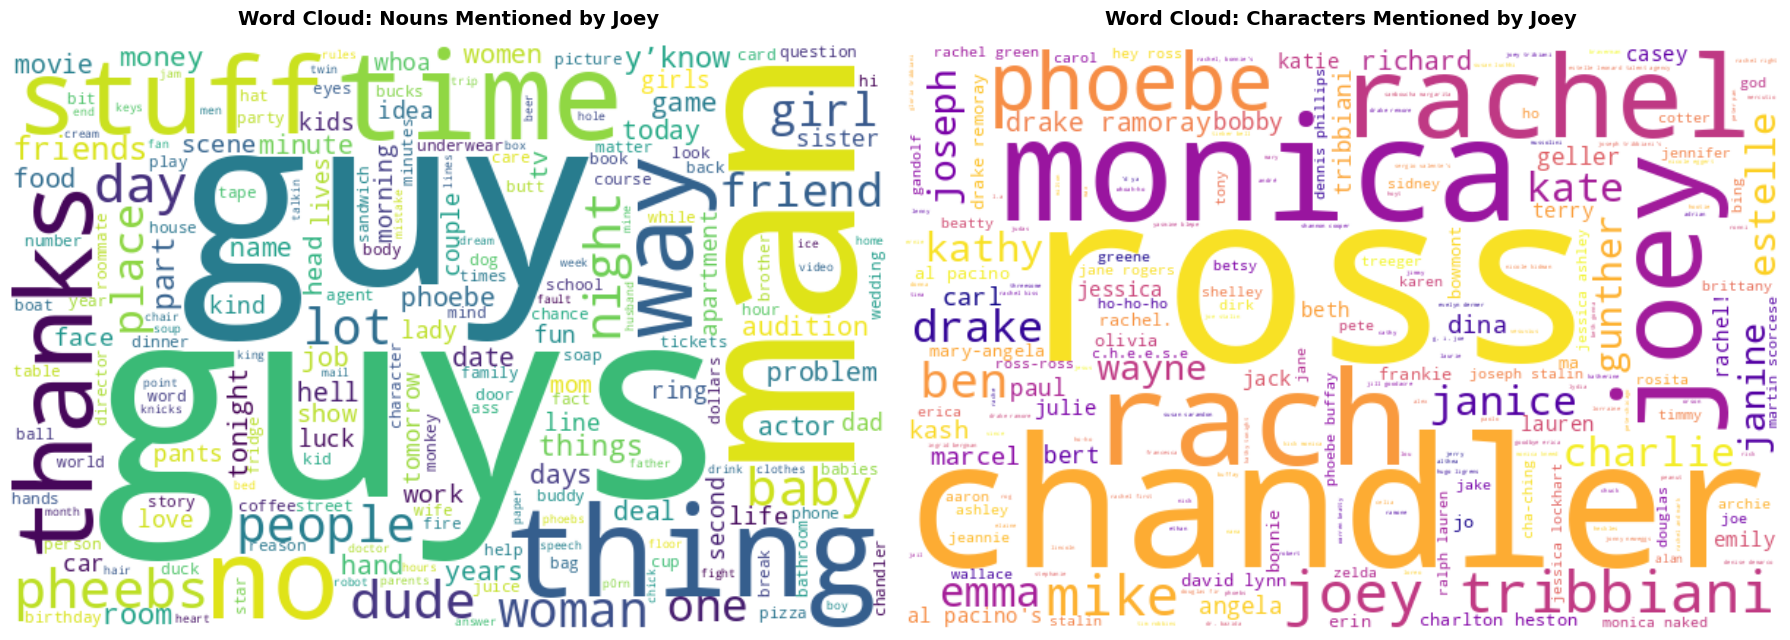

In [112]:
from wordcloud import WordCloud
from collections import Counter

#Extract nouns and character names separately
nouns_list = []
characters_list = []

#Extract common nouns from POS
for pos_list in friends_Joey["POS"]:
    for token, pos in pos_list:
        if pos == "NOUN":
            if len(token) > 1:
                nouns_list.append(token.lower())

#Extract person names from NER
for ner_list in friends_Joey["NER"]:
    for entity, label in ner_list:
        if label == "PERSON":
            if len(entity) > 1:
                characters_list.append(entity.lower())

#Generate frequency dictionaries
noun_frequencies = Counter(nouns_list)
character_frequencies = Counter(characters_list)

#Create WordClouds for both categories
wordcloud_nouns = WordCloud(
    width=600,
    height=400,
    background_color='white',
    colormap='viridis'
).generate_from_frequencies(noun_frequencies)

wordcloud_characters = WordCloud(
    width=600,
    height=400,
    background_color='white',
    colormap='plasma'
).generate_from_frequencies(character_frequencies)

#Display both Word Clouds side-by-side
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Nouns Word Cloud
axes[0].imshow(wordcloud_nouns, interpolation='bilinear')
axes[0].axis('off')
axes[0].set_title("Word Cloud: Nouns Mentioned by Joey", fontsize=14, fontweight='bold', pad=15)

# Characters Word Cloud
axes[1].imshow(wordcloud_characters, interpolation='bilinear')
axes[1].axis('off')
axes[1].set_title("Word Cloud: Characters Mentioned by Joey", fontsize=14, fontweight='bold', pad=15)

plt.tight_layout()
plt.show()

3. What are the most important words mentioned by your character? Do this analysis
per episode, per season and overall over all 10 seasons. To achieve this task, please
first make a bag-of-words and/or use the TF-IDF statistical principle. Remark: You
can try to make a Wordcloud for visualization, based on the given bag-of-words.

In [113]:
##Bag of words
from sklearn.feature_extraction.text import CountVectorizer
#union of all words
friends_Joey["clean_text"] = friends_Joey["Words"].apply(lambda words: " ".join(words))

#overall
overall_corpus = [" ".join(friends_Joey["clean_text"])]
bow_vectorizer = CountVectorizer()
bow_matrix = bow_vectorizer.fit_transform(overall_corpus)

#frequent words
bow_df = pd.DataFrame({
    "word": bow_vectorizer.get_feature_names_out(),
    "count": bow_matrix.toarray().flatten()
}).sort_values(by="count", ascending=False)

#Top 50 words
print(bow_df.head(50)["word"])


2075          hey
5055         yeah
2433         know
3058           oh
3666        right
2550         like
3068         okay
4910         well
4701           uh
1839          get
2596         look
1891        gonna
1905          got
3716         ross
1879           go
3077          one
3560       really
4493        think
1894         good
940          come
4859         want
5025        would
3866          see
1966         guys
789      chandler
2675          man
2731         mean
1925        great
3806          say
2179          huh
2528          let
1887        going
1965          guy
1046        could
2575       little
4450         tell
313          back
4114        sorry
4394         take
4491        thing
2721        maybe
2572       listen
5043           ya
3067           ok
4100    something
4541         time
131            ah
4839         wait
3765         said
4945         whoa
Name: word, dtype: object


Some of this words are clearly stop/filler words specific to this data set (more conversational), we are going to clean them.

In [141]:
extra_stopwords = {"hey", "yeah", "oh", "okay", "ok", "well", "uh", "um", "huh", "like", "really", "that", "could", "would", ##added after boW
                   "alright","uhh","umm","uhm","woah","re","ah","whoo","hmm","ooh","whoa"} ##added after TF-IDF
#Bag of words overall without extra stop words
friends_Joey["clean_text"] = friends_Joey["Words"].apply(
    lambda words: " ".join([w for w in words if w not in extra_stopwords])
)

#overall
overall_corpus = [" ".join(friends_Joey["clean_text"])]
bow_vectorizer = CountVectorizer()
bow_matrix = bow_vectorizer.fit_transform(overall_corpus)

#frequent words
bow_df = pd.DataFrame({
    "word": bow_vectorizer.get_feature_names_out(),
    "count": bow_matrix.toarray().flatten()
}).sort_values(by="count", ascending=False)

#Top 15 words
print(bow_df.head(15)["word"])

2428     know
3656    right
1837      get
2590     look
1889    gonna
1903      got
3706     ross
1877       go
3069      one
4483    think
1892     good
939      come
4844     want
3856      see
1964     guys
Name: word, dtype: object


In [142]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

## Per season bag of words
season_docs = friends_Joey.groupby("Season")["clean_text"].apply(lambda texts: " ".join(texts))

# Frequent words
bow_season_vec = CountVectorizer()
bow_season_matrix = bow_season_vec.fit_transform(season_docs)
feature_names_bow = bow_season_vec.get_feature_names_out()

print("\nPER SEASON - 10 most frequent words (BoW)")
for idx, season in enumerate(season_docs.index):
    row = bow_season_matrix[idx].toarray().flatten()
    top_indices = row.argsort()[-10:][::-1]
    top_words = [feature_names_bow[i] for i in top_indices]
    season_num = season.replace("Season-", "")
    print(f"season {int(season_num)} {', '.join(top_words)}")

## TF-IDF
tfidf_season = TfidfVectorizer(max_df=0.8)
tfidf_matrix_season = tfidf_season.fit_transform(season_docs)
feature_names_tfidf = tfidf_season.get_feature_names_out()

print("\nPER SEASON - 10 most frequent words (TF-IDF, words used in more than 8 seasons are ignored) ")
for idx, season in enumerate(season_docs.index):
    row = tfidf_matrix_season[idx].toarray().flatten()
    top_indices = row.argsort()[-10:][::-1]
    top_words = [feature_names_tfidf[i] for i in top_indices]
    season_num = season.replace("Season-", "")
    print(f"season {int(season_num)} {', '.join(top_words)}")


PER SEASON - 10 most frequent words (BoW)
season 1 know, right, go, got, ross, think, come, get, one, look
season 2 know, get, one, got, good, go, gonna, right, look, see
season 3 know, right, got, get, look, go, good, want, one, think
season 4 know, right, get, gonna, look, got, go, ross, man, come
season 5 know, right, ross, look, get, gonna, good, pheebs, got, man
season 6 know, right, gonna, look, get, got, go, think, chandler, great
season 7 know, right, look, get, got, one, go, gonna, guys, want
season 8 know, right, go, get, ross, gonna, look, think, got, one
season 9 know, right, look, get, ross, think, go, come, gonna, said
season 10 know, gonna, right, get, think, ross, one, guys, look, good

PER SEASON - 10 most frequent words (TF-IDF, words used in more than 8 seasons are ignored) 
season 1 push, ursula, stalin, dunno, bob, marcel, mom, mon, monkey, pacino
season 2 phoebs, joseph, somethin, goin, ducks, juice, drake, julie, bijan, goo
season 3 kate, janice, beth, opposite,

In [143]:
## Per episode bag of words (grouped and sorted strictly in chronological order)
# We aggregate the texts grouping by Season and Episode
episode_docs = friends_Joey.groupby(["Season", "Episode"], sort=False)["clean_text"].apply(lambda texts: " ".join(texts)).reset_index()

# Extract clean series for vectorizers
corpus_episodes = episode_docs["clean_text"]
episode_names = episode_docs["Episode"]
season_names = episode_docs["Season"]

# Frequent words
bow_episode_vec = CountVectorizer()
bow_episode_matrix = bow_episode_vec.fit_transform(corpus_episodes)
feature_names_bow = bow_episode_vec.get_feature_names_out()

print("\nPER EPISODE - 10 most frequent words (BoW)")
for idx, episode in enumerate(episode_names):
    row = bow_episode_matrix[idx].toarray().flatten()
    top_indices = row.argsort()[-10:][::-1]
    top_words = [feature_names_bow[i] for i in top_indices]
    season_num = season_names[idx].replace("Season-", "")
    print(f"temporada {int(season_num)} - {episode} {{{', '.join(top_words)}}}")

## TF-IDF
tfidf_episode = TfidfVectorizer(max_df=0.8)
tfidf_matrix_episode = tfidf_episode.fit_transform(corpus_episodes)
feature_names_tfidf = tfidf_episode.get_feature_names_out()

print("\nPER EPISODE - 10 most frequent words (TF-IDF, words used in more than 80% of the episodes are ignored) ")
for idx, episode in enumerate(episode_names):
    row = tfidf_matrix_episode[idx].toarray().flatten()
    top_indices = row.argsort()[-10:][::-1]
    top_words = [feature_names_tfidf[i] for i in top_indices]
    season_num = season_names[idx].replace("Season-", "")
    print(f"season {int(season_num)} - {episode} {{{', '.join(top_words)}}}")


PER EPISODE - 10 most frequent words (BoW)
temporada 1 - Episode-01-The One Where Monica Gets a New Roommate (The Pilot) {something, got, real, paul, guy, date, ross, cannot, lot, get}
temporada 1 - Episode-02-The One With the Sonogram at the End {still, right, calm, getting, ya, see, would, folks, talking, seeing}
temporada 1 - Episode-03-The One With the Thumb {let, going, little, go, know, you, keep, it, cell, phoebe}
temporada 1 - Episode-04-The One With George Stephanopoulos {ross, hockey, ninety, sit, woman, mon, seven, first, tonight, stuff}
temporada 1 - Episode-05-The One With the East German Laundry Detergent {know, angela, bob, look, come, together, want, mississippi, little, wait}
temporada 1 - Episode-06-The One With the Butt {al, butt, pacino, order, see, know, think, big, agent, agency}
temporada 1 - Episode-07-The One With the Blackout {ross, zone, going, got, party, everyone, hah, tell, man, chandler}
temporada 1 - Episode-08-The One Where Nana Dies Twice {look, dead,

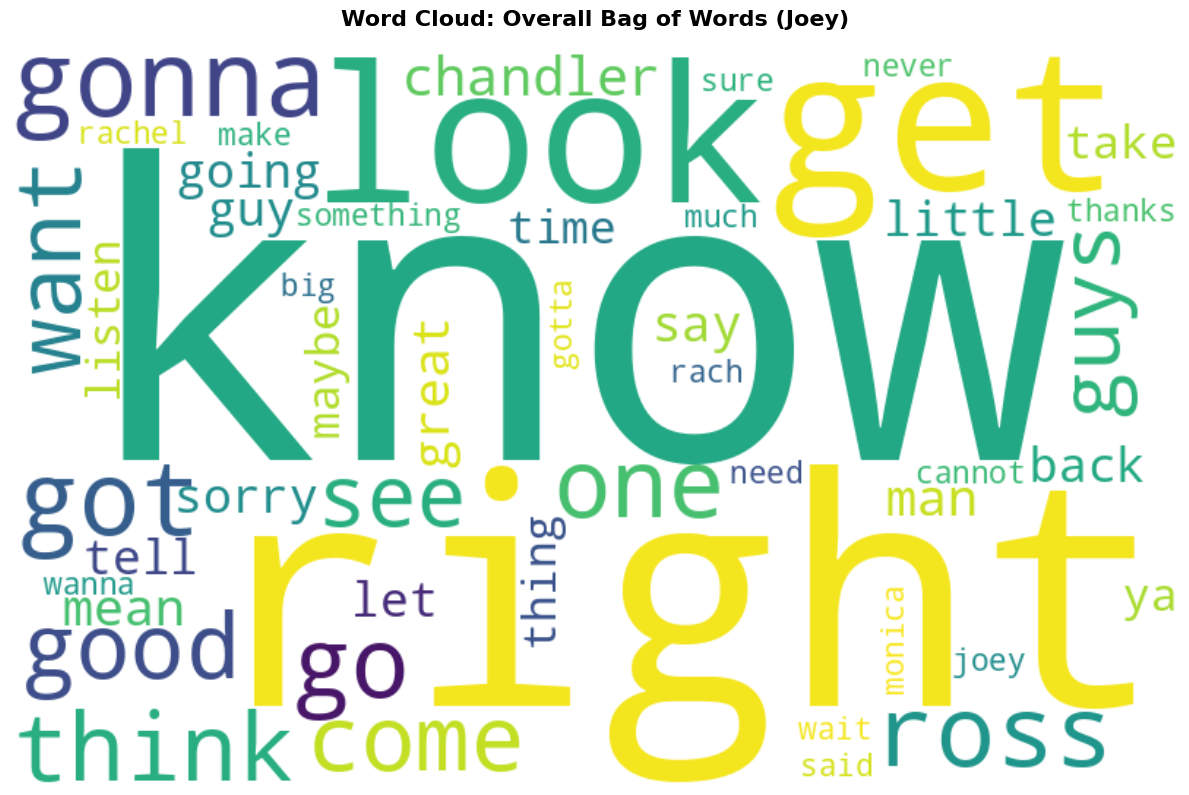

In [144]:
# Convert bow_df to a dictionary of word frequencies
bow_frequencies = dict(zip(bow_df["word"], bow_df["count"]))

# Create WordCloud for overall Bag of Words
wordcloud_bow = WordCloud(
    width=800,
    height=500,
    background_color='white',
    colormap='viridis',
    max_words=50
).generate_from_frequencies(bow_frequencies)

# Display the Word Cloud
plt.figure(figsize=(12, 8))
plt.imshow(wordcloud_bow, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud: Overall Bag of Words (Joey)", fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

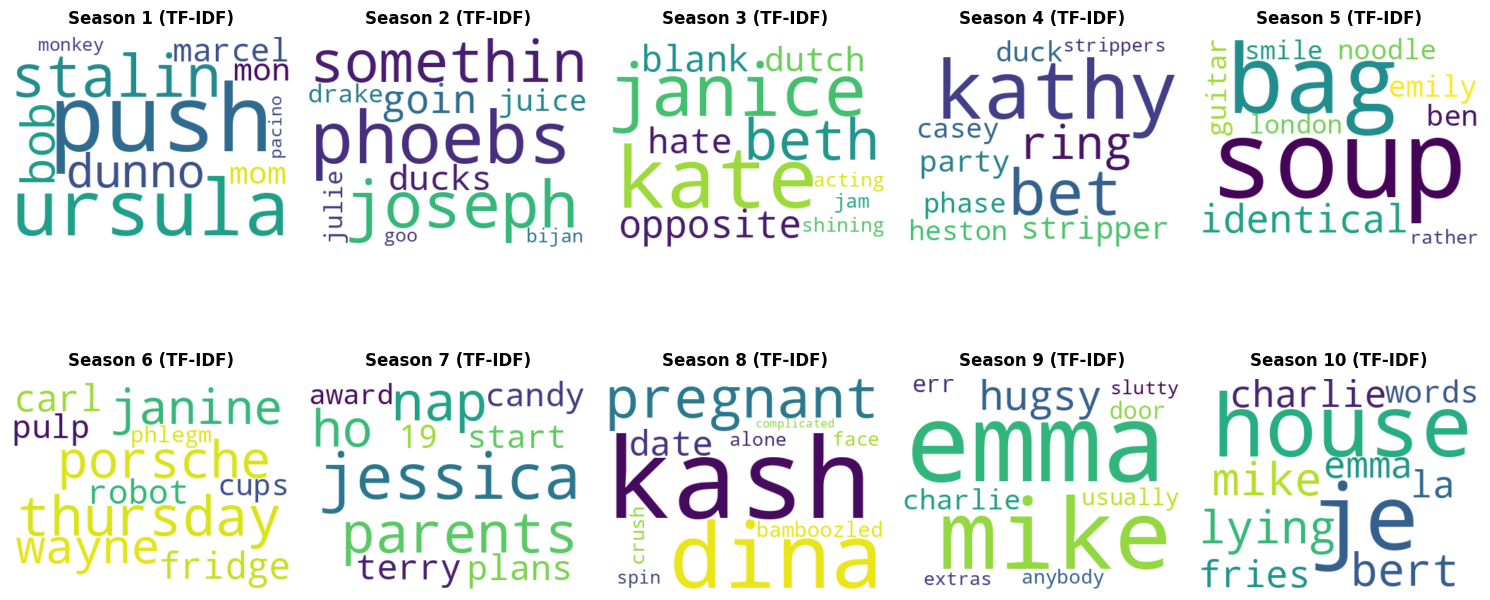

In [151]:
## WordCloud per Season using TF-IDF
# Create a grid of subplots for the 10 seasons
fig, axes = plt.subplots(2, 5, figsize=(15, 8))
axes = axes.flatten()

feature_names_tfidf = tfidf_season.get_feature_names_out()

for idx, (season, text) in enumerate(season_docs.items()):
    row_scores = tfidf_matrix_season[idx].toarray().flatten()
    season_tfidf_dict = {
        feature_names_tfidf[i]: row_scores[i]
        for i in row_scores.argsort()[-10:][::-1] if row_scores[i] > 0
    }

    wordcloud = WordCloud(
        width=400,
        height=300,
        background_color='white',
        colormap='viridis',
        max_words=10
    ).generate_from_frequencies(season_tfidf_dict)

    axes[idx].imshow(wordcloud, interpolation='bilinear')
    axes[idx].axis('off')
    season_num = season.replace("Season-", "")
    axes[idx].set_title(f"Season {int(season_num)} (TF-IDF)", fontsize=12, fontweight='bold', pad=10)

plt.tight_layout()
plt.show()

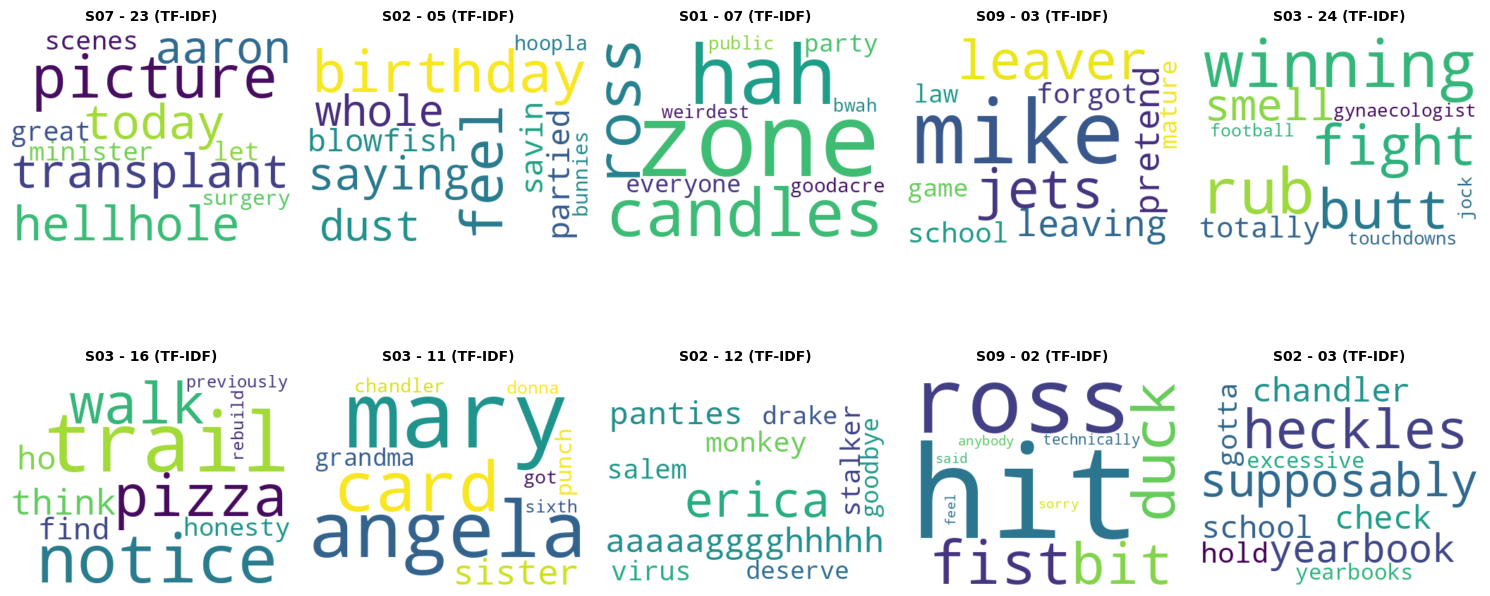

In [152]:
## WordCloud per 10 Random Episodes using TF-IDF
import random
import numpy as np

# Select 10 random episode indices
random.seed(42)  # Maintain reproducibility
random_indices = random.sample(range(len(episode_docs)), 10)

# Configure subplot grid (2 rows, 5 columns)
fig, axes = plt.subplots(2, 5, figsize=(15, 8))
axes = axes.flatten()

feature_names_tfidf_ep = tfidf_episode.get_feature_names_out()

for idx, ep_idx in enumerate(random_indices):
    # Retrieve episode metadata
    season = episode_docs.loc[ep_idx, "Season"]
    episode = episode_docs.loc[ep_idx, "Episode"]

    # Get TF-IDF scores for the current episode
    row_scores = tfidf_matrix_episode[ep_idx].toarray().flatten()

    # Create a frequency dictionary based on TF-IDF scores
    ep_tfidf_dict = {
        feature_names_tfidf_ep[i]: row_scores[i]
        for i in row_scores.argsort()[-10:][::-1] if row_scores[i] > 0
    }

    # Generate word cloud
    wordcloud = WordCloud(
        width=400,
        height=300,
        background_color='white',
        colormap='viridis',
        max_words=10
    ).generate_from_frequencies(ep_tfidf_dict)

    # Display in the corresponding subplot
    axes[idx].imshow(wordcloud, interpolation='bilinear')
    axes[idx].axis('off')

    season_num = season.replace("Season-", "S")
    ep_num = episode.split("-")[1] if "-" in episode else ""
    axes[idx].set_title(f"{season_num} - {ep_num[:15]} (TF-IDF)", fontsize=10, fontweight='bold', pad=10)

plt.tight_layout()
plt.show()

4. Examine the co-occurence of words for your character by using the Positive Pointwise
Mutual Information measurement. Which words are commonly used together in
his/her dialogues? Remark: You can try to make a Word-Word co-occurrence matrix.

In [156]:
# 1. Create a binary Document-Term matrix at the dialogue-line level
# min_df=5 filters out ultra-rare words that appear only a few times (prevents classic PMI bias)
vec_cooc = CountVectorizer(min_df=5, binary=True)
X = vec_cooc.fit_transform(friends_Joey["clean_text"])
vocab = vec_cooc.get_feature_names_out()

# 2. Build the Word-Word co-occurrence matrix (C = X^T * X)
C = (X.T @ X).toarray().astype(float)

# Set the main diagonal to 0 (avoid counting self-co-occurrences)
np.fill_diagonal(C, 0)

# 3. Compute probabilities and PPMI
total_pairs = C.sum()
row_sums = C.sum(axis=1, keepdims=True)
col_sums = C.sum(axis=0, keepdims=True)

# Expected co-occurrences under independence: P(w1) * P(w2) * total_pairs
expected = (row_sums @ col_sums) / total_pairs

# Compute PMI while safely ignoring division by zero or log(0)
with np.errstate(divide="ignore", invalid="ignore"):
    pmi = np.log2(C / expected)

# PPMI: keep only positive values (replace negatives and NaNs/infs with 0)
ppmi = np.maximum(0, np.nan_to_num(pmi, nan=0.0, posinf=0.0, neginf=0.0))

# 4. Extract Top 20 word pairs by PPMI (using upper triangle to avoid duplicate (A,B) and (B,A) pairs)
upper_idx = np.triu_indices_from(ppmi, k=1)
pairs_df = pd.DataFrame({
    "word_1": vocab[upper_idx[0]],
    "word_2": vocab[upper_idx[1]],
    "co_occurrences": C[upper_idx].astype(int),
    "ppmi": ppmi[upper_idx]
})

# Keep pairs that co-occurred at least 3 times for robustness
top_ppmi = (
    pairs_df[pairs_df["co_occurrences"] >= 3]
    .sort_values(by="ppmi", ascending=False)
    .head(20)
)

print(top_ppmi.to_string(index=False))

   word_1  word_2  co_occurrences      ppmi
     rock    roll               3 10.613658
    judge   rules               4 10.527928
   noodle    soup               5 10.119843
     carl  damnit               3  8.621037
       al  pacino               7  8.503854
     emma   hugsy               5  8.170918
    chick    duck               6  8.082011
      fit   grown               3  8.068496
    bucks    cost               3  7.910955
      fit    unit               3  7.800008
identical    twin               6  7.755677
      war   world               3  7.666125
    grown    unit               3  7.625978
christmas   trees               3  7.555353
   camera   video               4  7.492812
 bachelor   party               4  7.387590
    extra  ticket               5  7.306229
   knicks tickets               5  7.291141
   angela    mary               3  7.282924
   months     six               3  7.274171
